<h1 align='center' style='color:blue'>ML Leacture With Ananta Patil: Credit Risk Modeling Project</h1>

In [2]:
# %pip install pandas numpy scipy scikit-learn matplotlib seaborn plotly xgboost lightgbm statsmodels joblib streamlit jupyterlab torch torchvision tensorflow keras transformers nltk spacy

### Load Data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt                     
import seaborn as sns            
import numpy as np              

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.float_format', lambda x: "{:.2f}".format(x))
np.set_printoptions(suppress=True)

In [4]:
df_customers = pd.read_csv(r'D:\Practice\Project 2\customers.csv')
df_loans = pd.read_csv(r"D:\Practice\Project 2\loans.csv")
df_bureau = pd.read_csv(r'D:\Practice\Project 2\bureau_data.csv')

display(df_customers.shape, df_loans.shape, df_bureau.shape )

(50000, 12)

(50000, 15)

(50000, 8)

In [5]:
display(df_customers.head(2), df_loans.head(2), df_bureau.head(2) )

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001


,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4


In [6]:
df=pd.merge(df_customers, df_loans, on = "cust_id").merge(df_bureau, on = 'cust_id')
df

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,2019-07-24,2019-08-09,False,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,2019-07-24,2019-08-02,False,4,2,120,0,0,5,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,C49996,40,F,Single,Salaried,775000,2,Owned,11,Chennai,...,2024-07-22,2024-08-15,False,4,2,165,1,6,8,24
49996,C49997,39,M,Single,Salaried,3117000,0,Owned,9,Kolkata,...,2024-07-22,2024-07-29,False,4,0,161,0,0,4,91
49997,C49998,45,F,Single,Self-Employed,1329000,0,Rented,27,Bangalore,...,2024-07-22,2024-07-25,False,4,1,42,0,0,7,38
49998,C49999,42,F,Single,Self-Employed,533000,2,Mortgage,20,Hyderabad,...,2024-07-22,2024-07-29,False,1,2,42,9,47,4,17


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  str    
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  str    
 3   marital_status               50000 non-null  str    
 4   employment_status            50000 non-null  str    
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  str    
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  str    
 10  state                        50000 non-null  str    
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  str    
 13  loan_purpose               

<h3 align="center" style="color:blue">Data Cleaning</h3>

In [8]:
df['default'] = df['default'].astype('int')
df['default'].value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

In [9]:
df.isnull().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 62
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
default                         0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_mon

In [10]:
df.residence_type.mode()[0]

'Owned'

In [11]:
df['residence_type'] = df.residence_type.fillna(value=df.residence_type.mode()[0], inplace=True)

### Box plot to visualize outliers

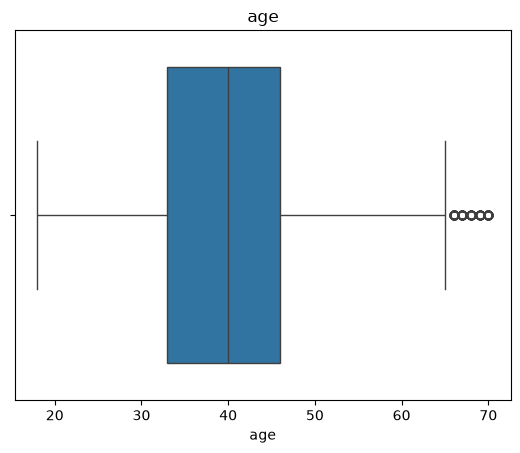

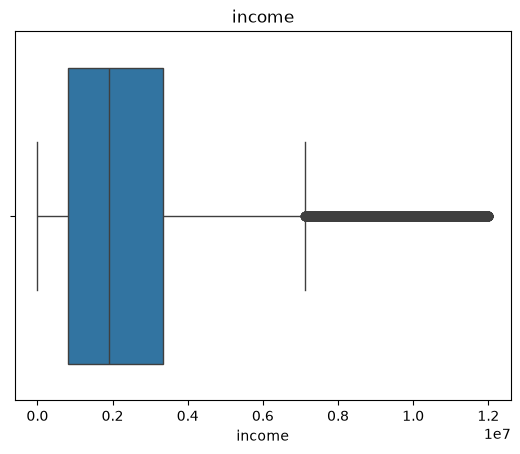

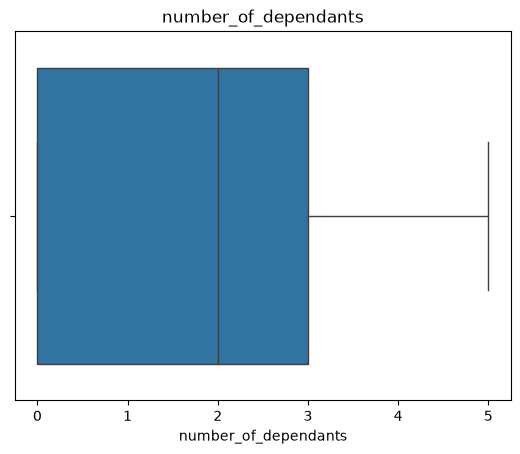

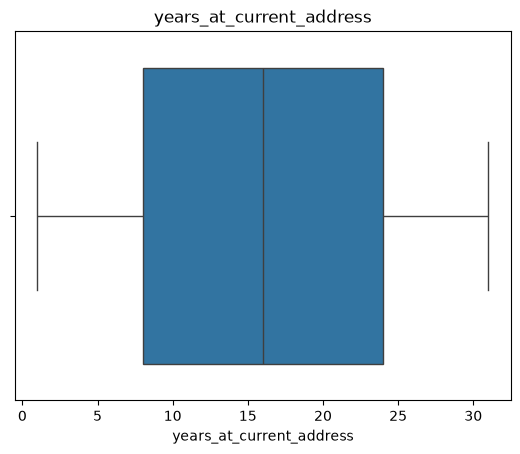

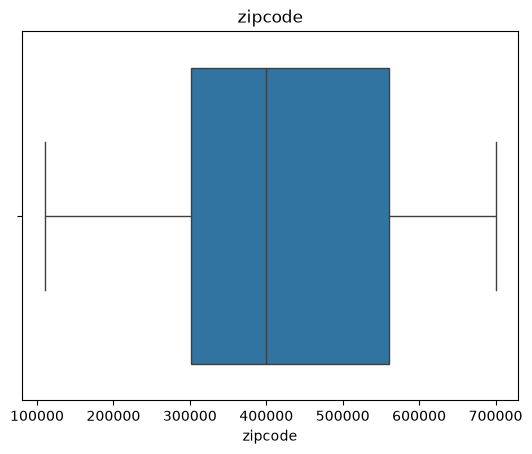

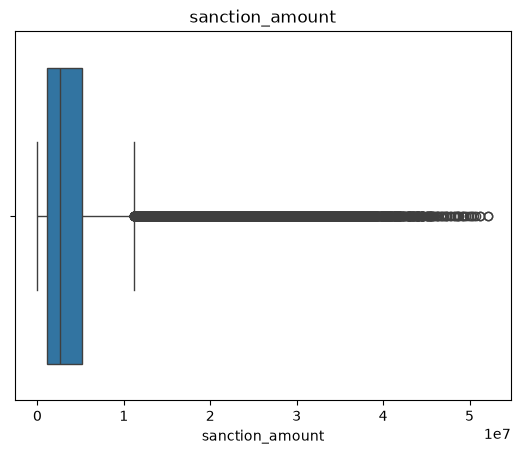

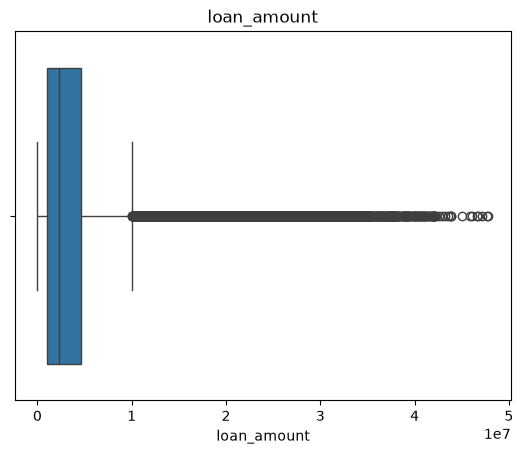

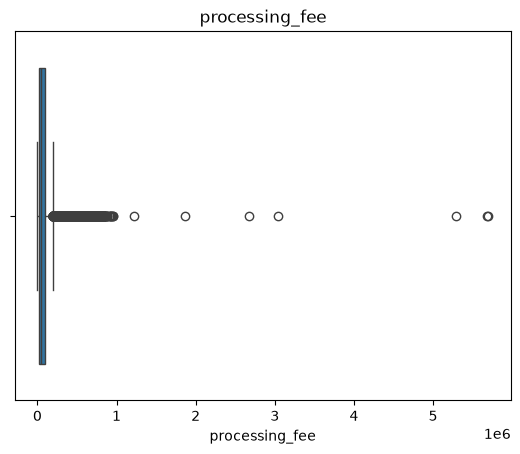

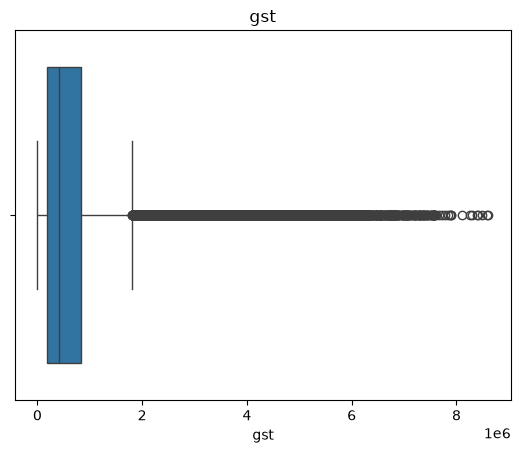

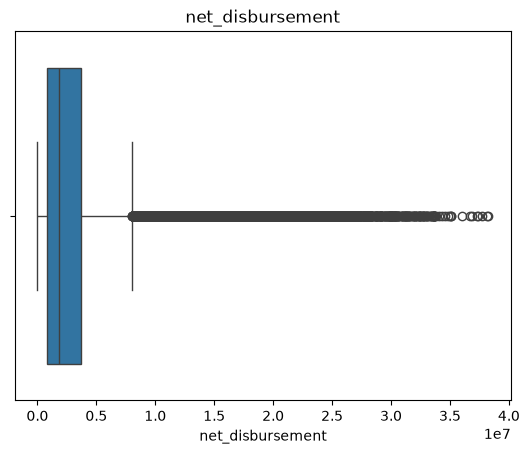

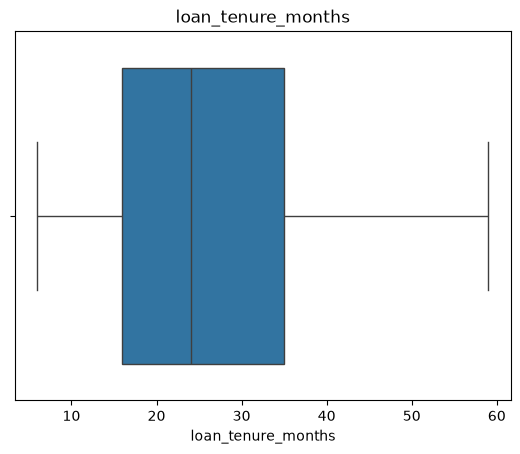

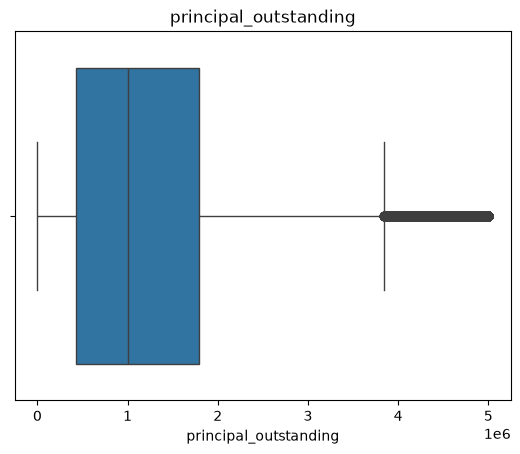

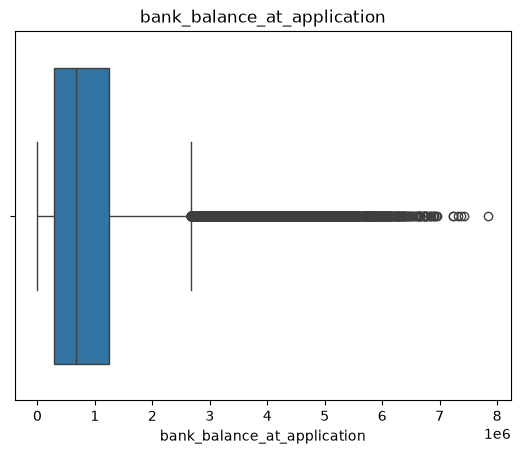

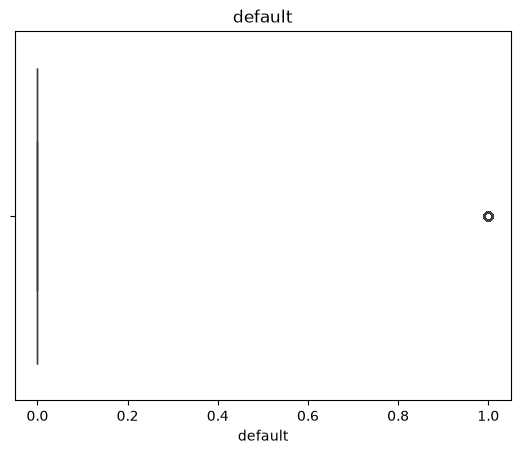

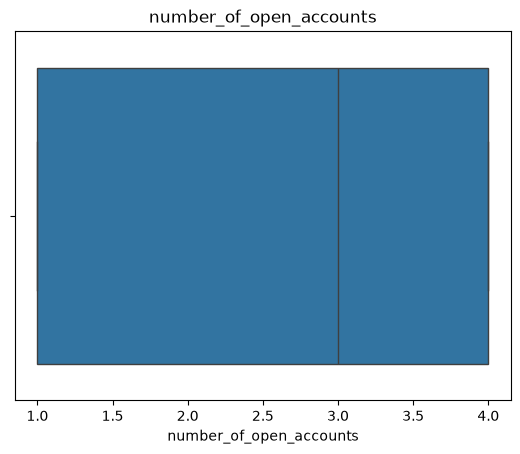

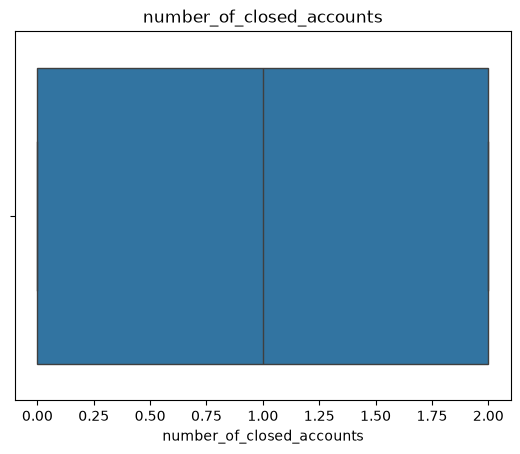

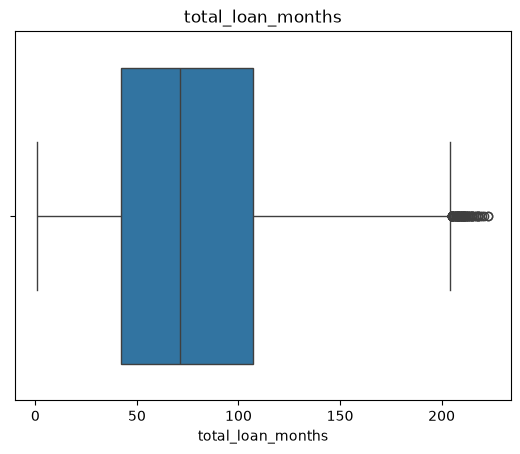

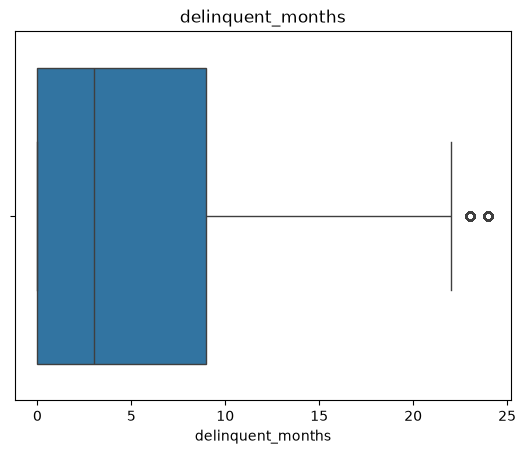

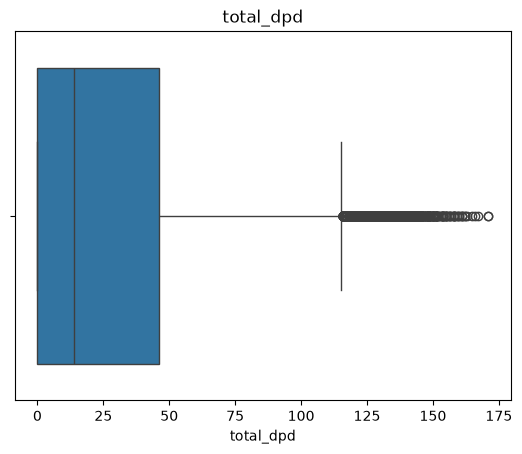

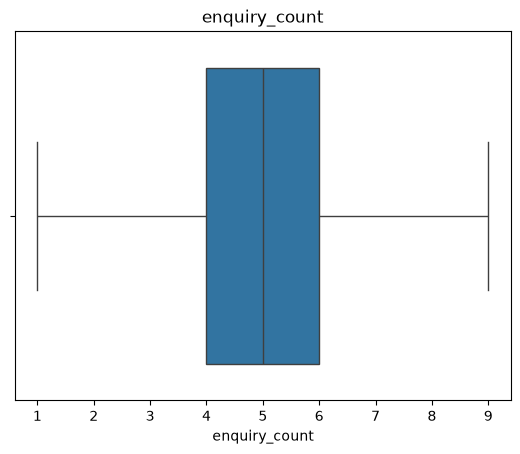

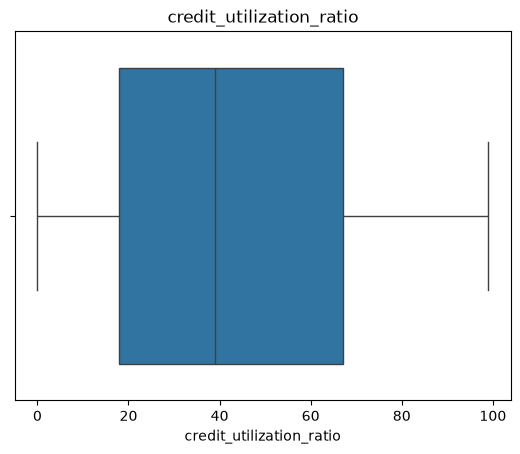

In [12]:
for col in df.select_dtypes(exclude="object").columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

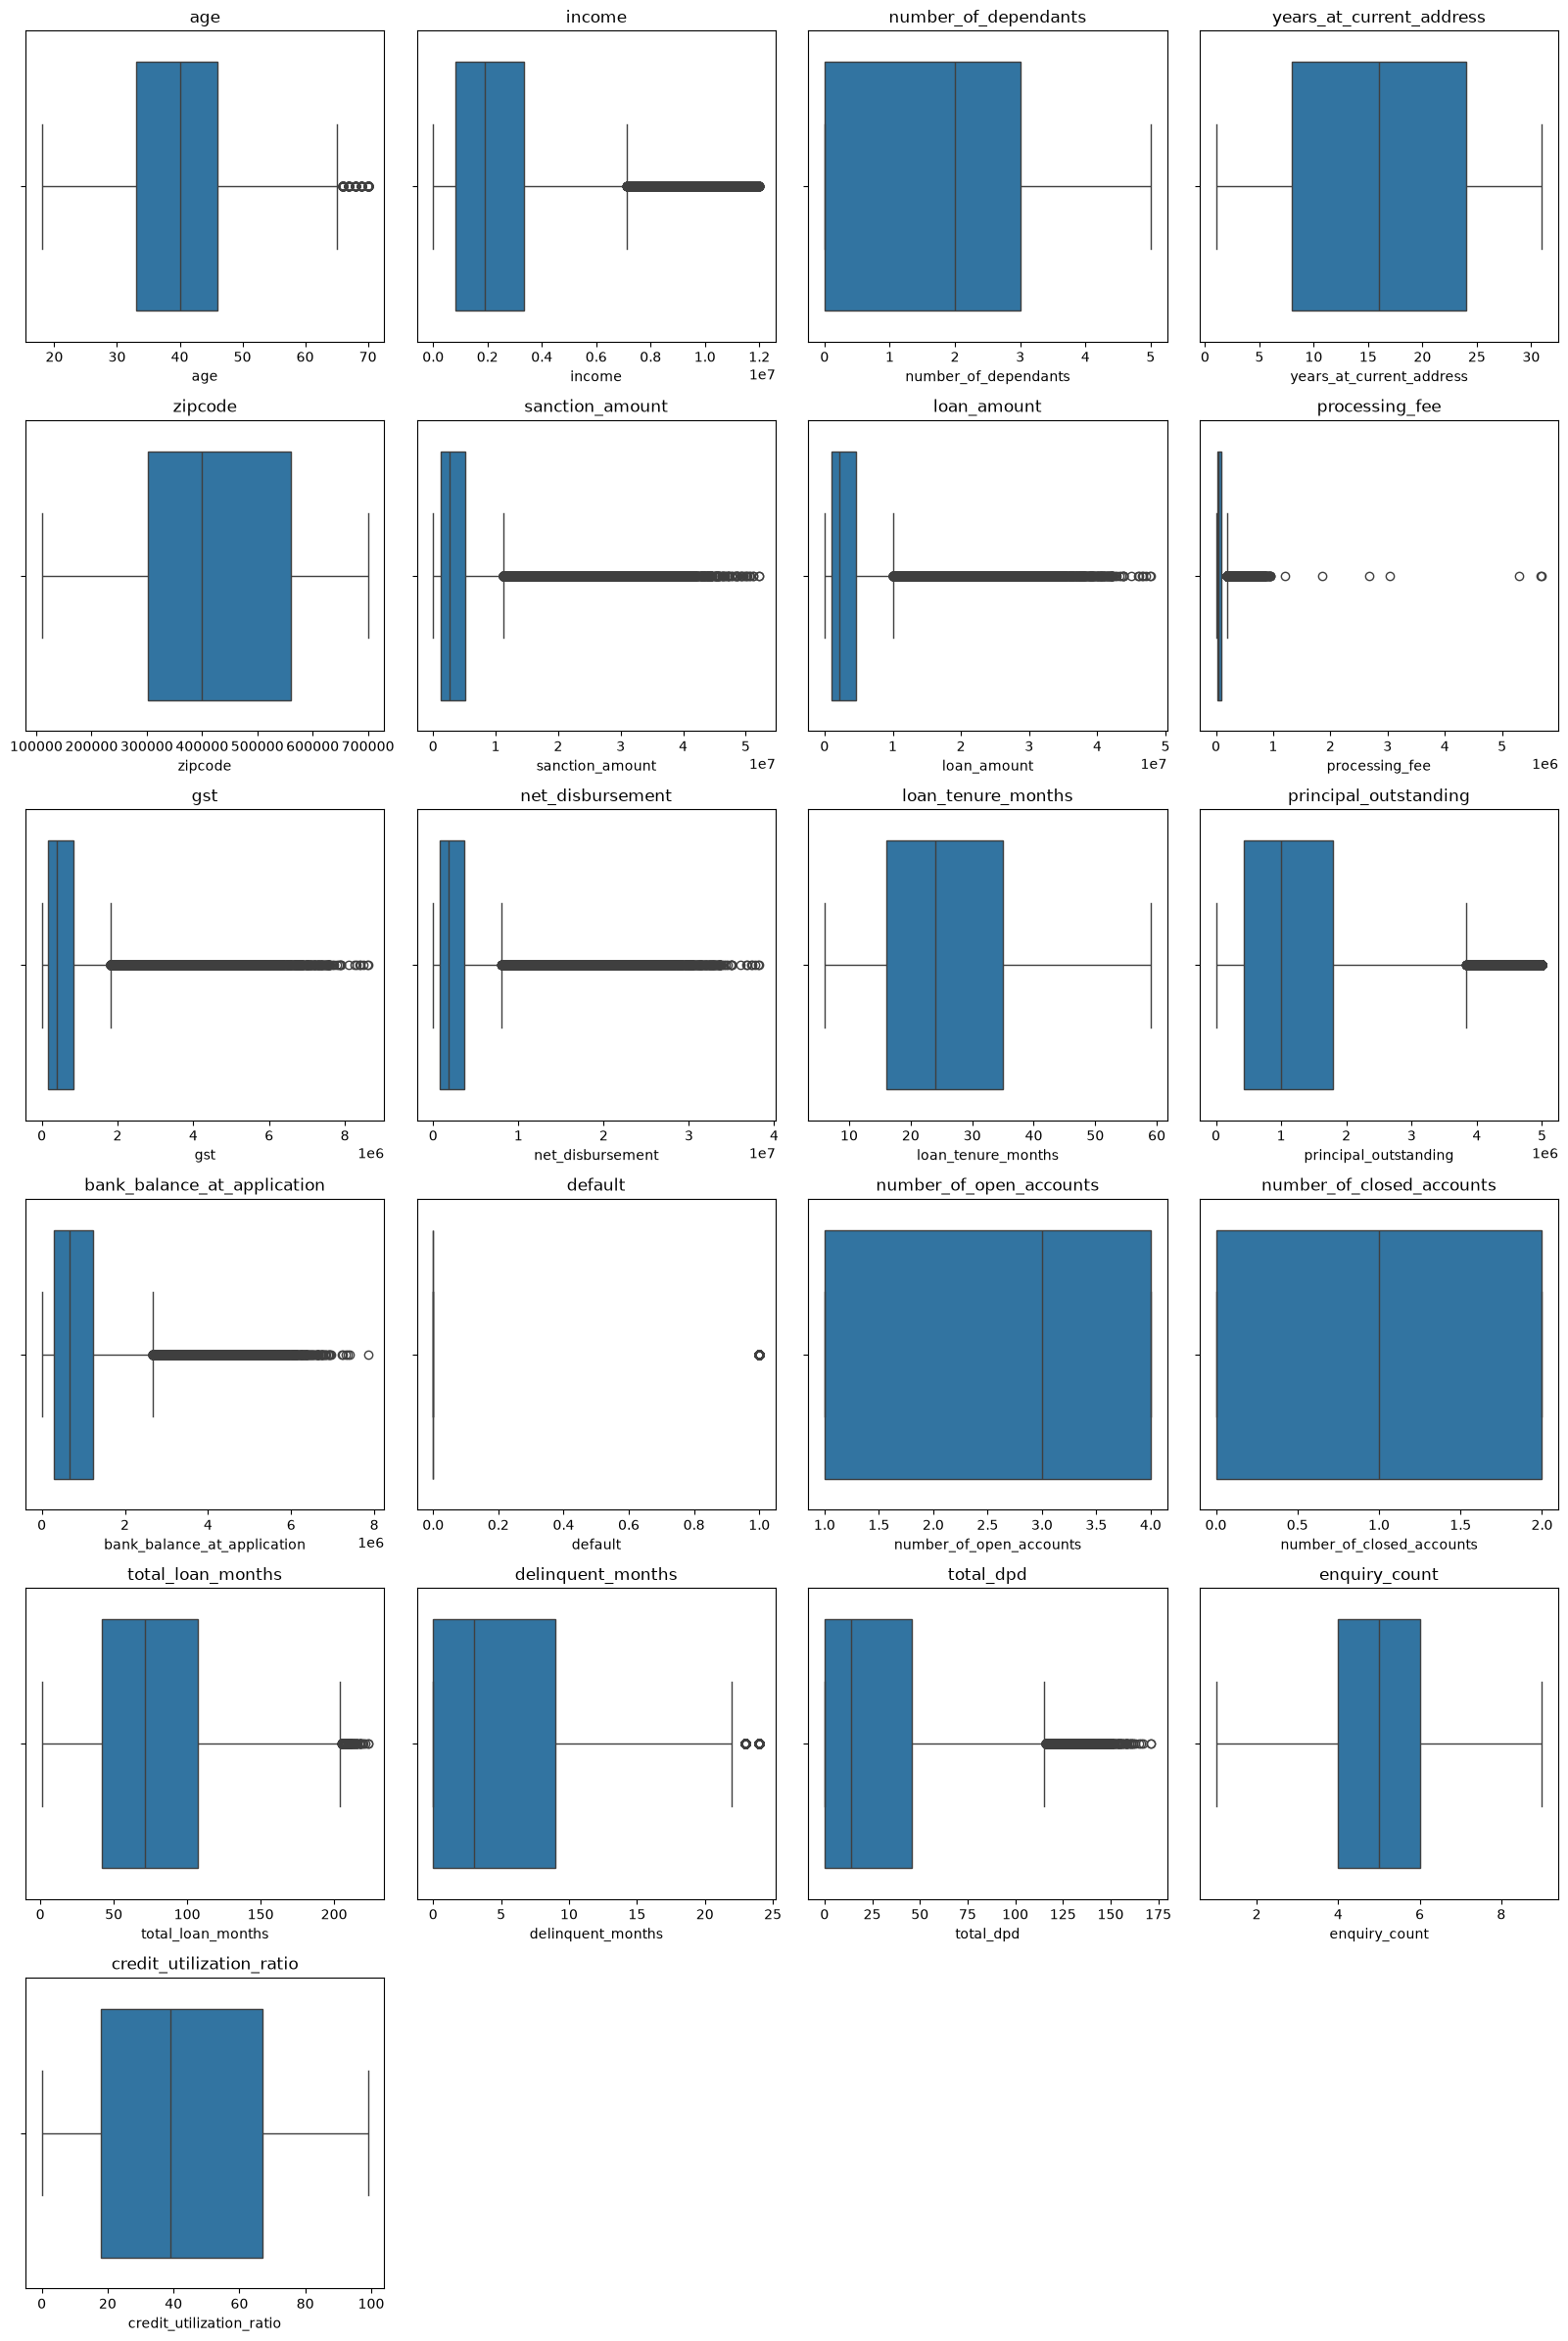

In [13]:
import math
import matplotlib.pyplot as plt
import seaborn as sns


cols = df.select_dtypes(exclude="object").columns
ncols = 4
nrows = math.ceil(len(cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

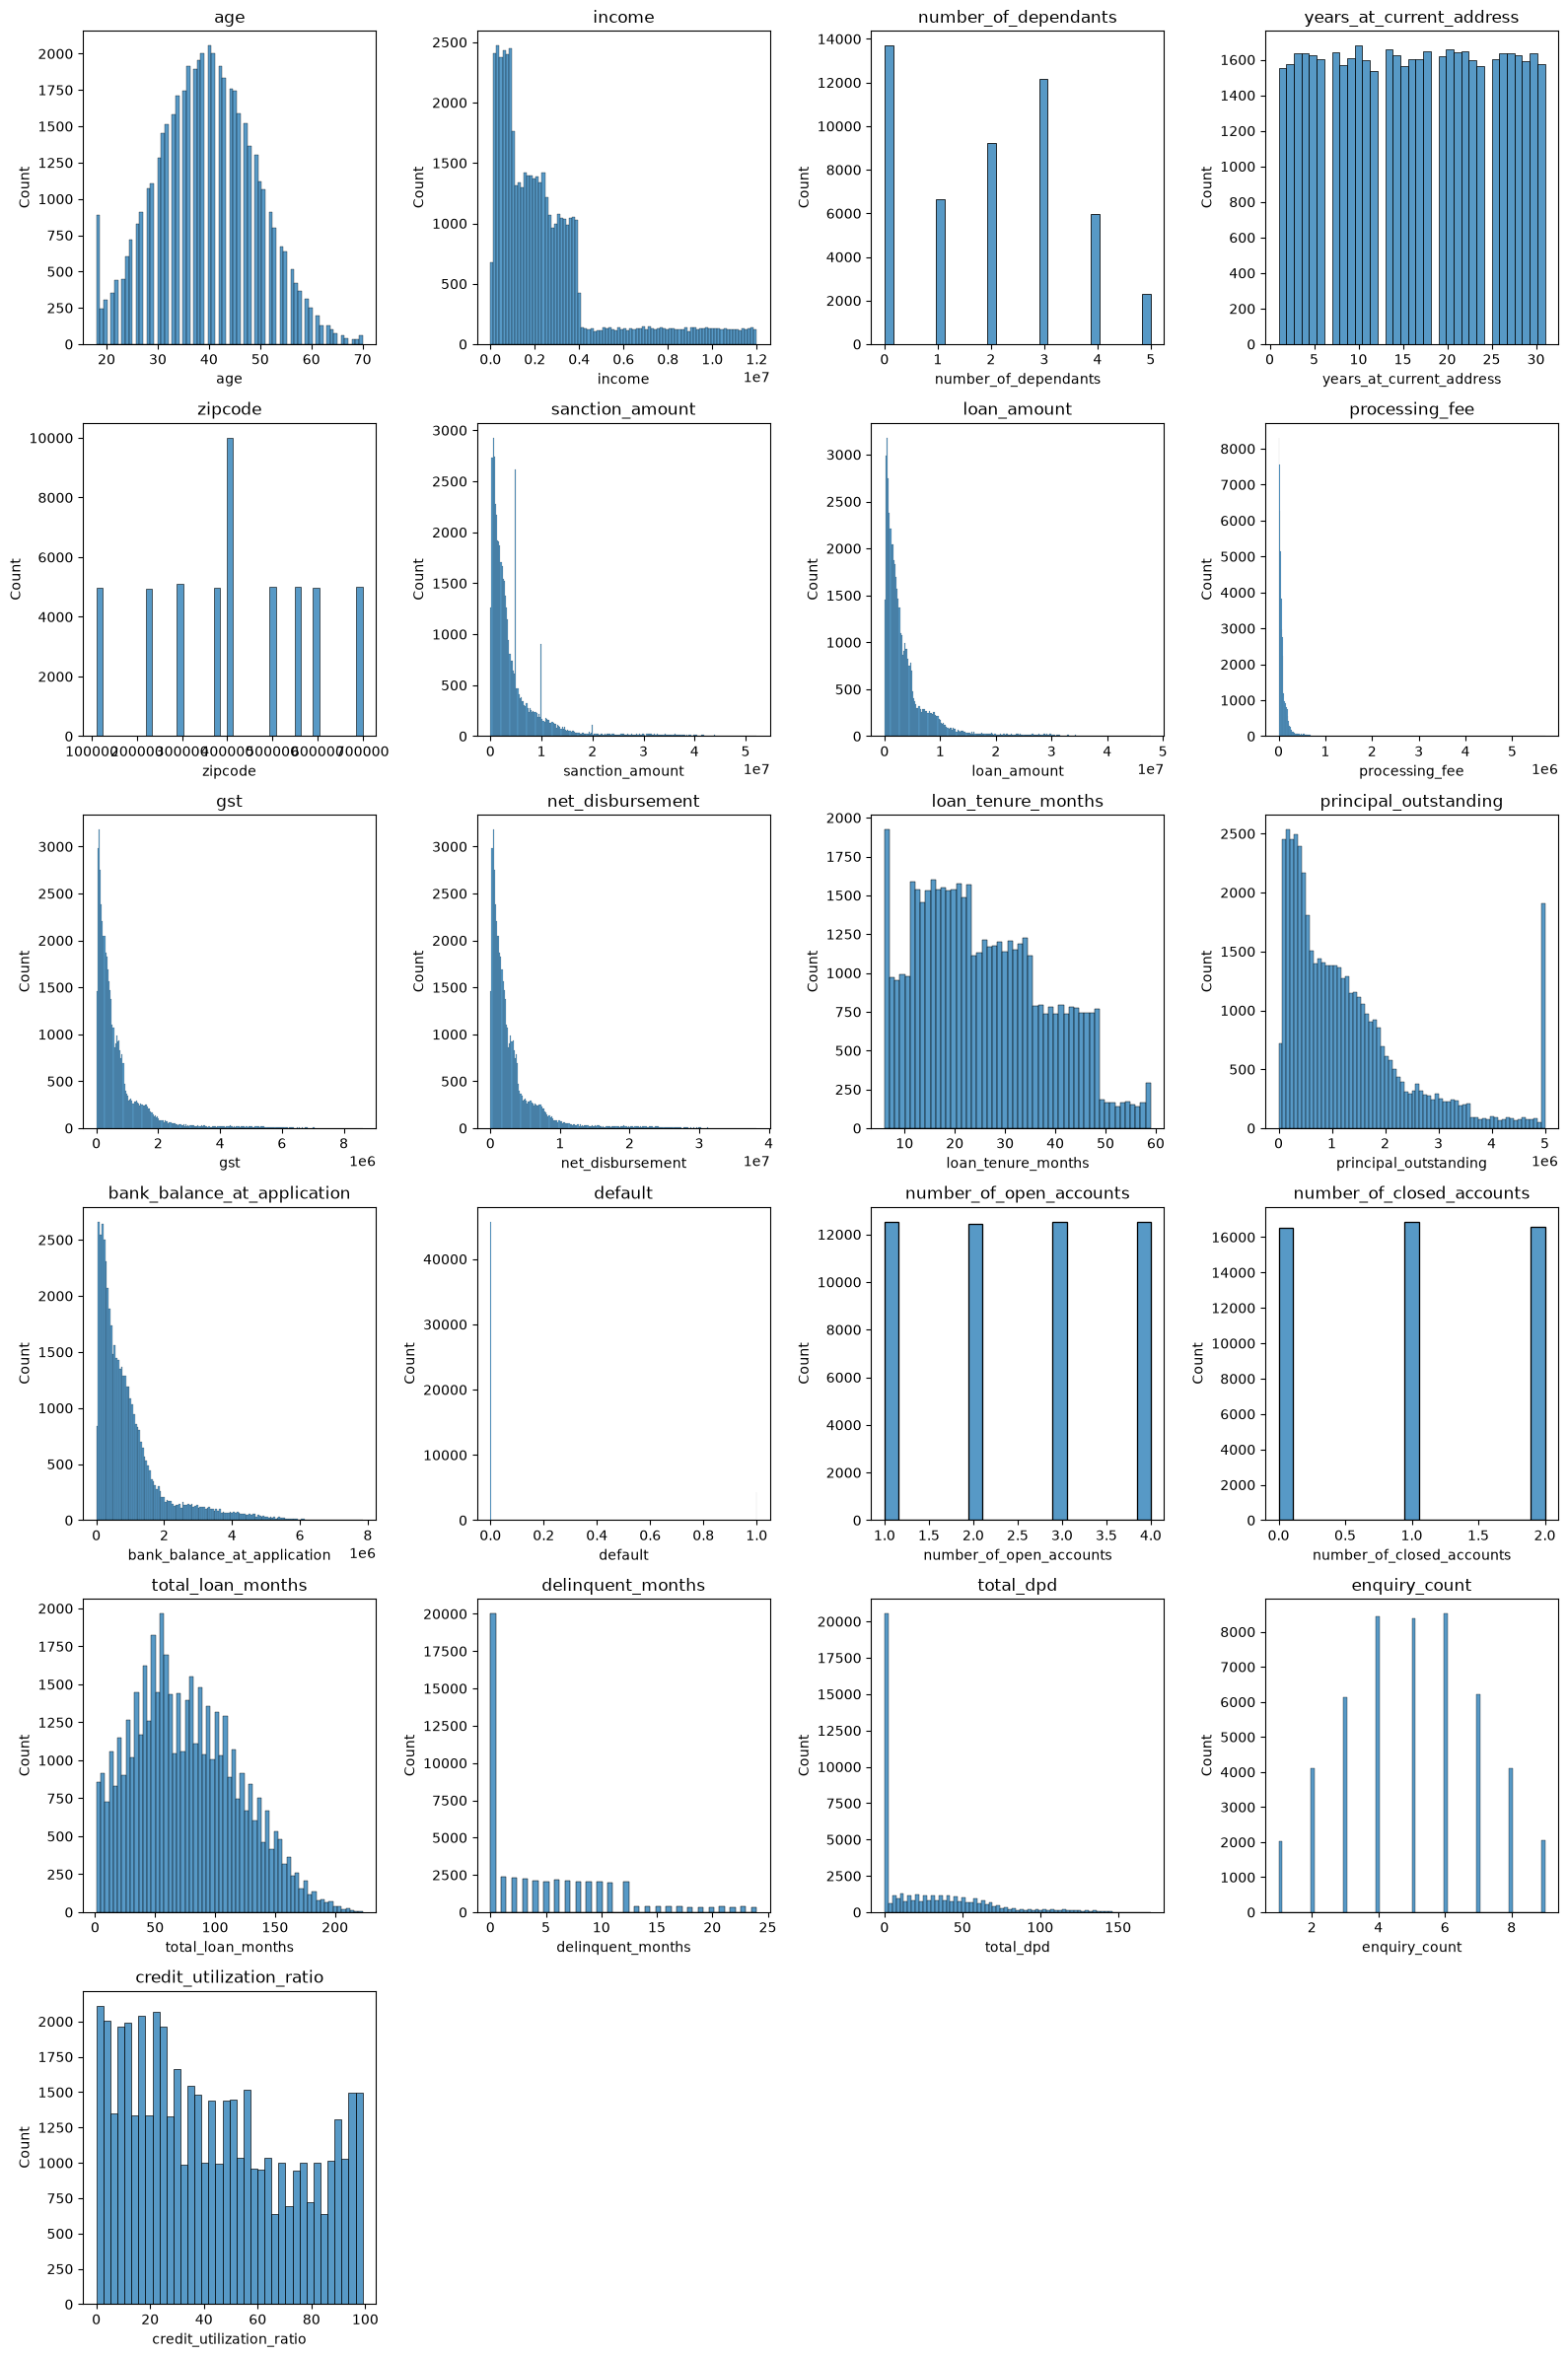

In [14]:
import math
import matplotlib.pyplot as plt
import seaborn as sns


cols = df.select_dtypes(exclude="object").columns
ncols = 4
nrows = math.ceil(len(cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Outlier Removal: Processing Fee

In [15]:
df.processing_fee.describe()

count     50000.00
mean      80494.71
std      117312.26
min           0.00
25%       19340.00
50%       44800.00
75%       92240.00
max     5698029.90
Name: processing_fee, dtype: float64

In [16]:
df[ df.processing_fee == df.processing_fee.max()] [['loan_amount', 'processing_fee']]

,loan_amount,processing_fee
12294,4639000,5698029.90


In [17]:
df[ df.processing_fee > df.loan_amount] [['loan_amount', 'processing_fee']]

,loan_amount,processing_fee
9898,3626000,5293543.52
12294,4639000,5698029.90
23981,2234000,2669791.02
28174,966000,1214492.67
29305,2616000,3036378.01
33705,3812000,5678020.86
47089,1738000,1858964.77


In [18]:
# processing_fee on the loan amount is 3% only 

df[ (df.processing_fee/df.loan_amount) > 0.03 ][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee
9898,3626000,5293543.52
12294,4639000,5698029.90
23981,2234000,2669791.02
28174,966000,1214492.67
29305,2616000,3036378.01
33705,3812000,5678020.86
47089,1738000,1858964.77


In [19]:
df = df[ (df.processing_fee/df.loan_amount) < 0.03 ]

In [20]:
# Use other business rules for data validation
# Rule 1: GST should not be more than 20%

df[(df.gst/df.loan_amount)>0.2].shape

(0, 33)

In [21]:
# Rule 2: Net disbursement should not be higher than loan_amount
df[df.net_disbursement>df.loan_amount].shape

(0, 33)

No rows found that breaks rule 1 and rule 2

### Analyze Categorical Columns

In [22]:
for col in df.select_dtypes(include="object").columns:
    print("\nColumn Name -:", df[col].unique())
   


Column Name -: <ArrowStringArray>
['C00001', 'C00002', 'C00003', 'C00004', 'C00005', 'C00006', 'C00007',
 'C00008', 'C00009', 'C00010',
 ...
 'C49991', 'C49992', 'C49993', 'C49994', 'C49995', 'C49996', 'C49997',
 'C49998', 'C49999', 'C50000']
Length: 49985, dtype: str

Column Name -: <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str

Column Name -: <ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str

Column Name -: <ArrowStringArray>
['Self-Employed', 'Salaried']
Length: 2, dtype: str

Column Name -: <ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str

Column Name -: <ArrowStringArray>
[    'Delhi',   'Chennai',   'Kolkata', 'Bangalore',      'Pune',    'Jaipur',
   'Lucknow',    'Mumbai', 'Ahmedabad', 'Hyderabad']
Length: 10, dtype: str

Column Name -: <ArrowStringArray>
[        'Delhi',    'Tamil Nadu',   'West Bengal',     'Karnataka',
   'Maharashtra',     'Rajasthan', 'Uttar Pradesh',       'Gujarat',
     'Telangana']
Length: 9, dtype: str

Col

### Fix Errors in Loan Purpose Column

In [23]:
### Fix Errors in Loan Purpose Column
df['loan_purpose'] = df['loan_purpose'].replace('Personaal', 'Personal')
df['loan_purpose'].unique()
df['loan_purpose'] = df['loan_purpose'].replace('Personaal', 'Personal')
df['loan_purpose'].unique()

<ArrowStringArray>
['Auto', 'Home', 'Personal', 'Education']
Length: 4, dtype: str

<h3 style="color:blue" align="center">Exploratory Data Analysis</h3>

### Age Column

In [24]:
df.groupby("default")['age'].describe()

,count,mean,std,min,25%,50%,75%,max
default,,,,,,,,
0,45688.00,39.76,9.87,18.00,33.00,40.00,46.00,70.00
1,4297.00,37.29,9.33,18.00,31.00,37.00,44.00,70.00


**Insights**

1. Average age in the default group is little less (37.12) than the average (39.7) of the group that did not default
1. Variability (standard deviation) is mostly similar in both the groups
1. Both the groups have similar min and max ages

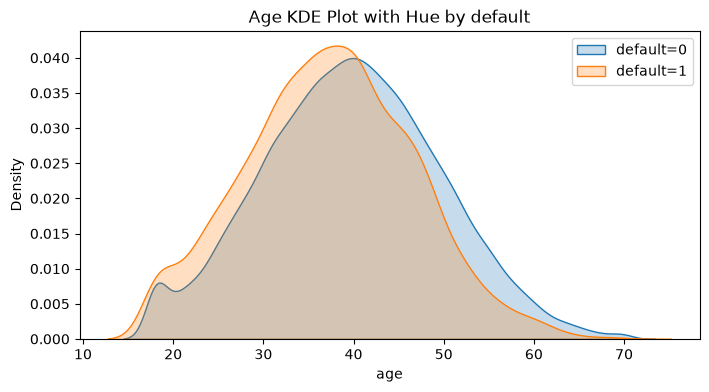

In [25]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df['age'][df['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df['age'][df['default'] == 1], fill=True, label='default=1')
plt.title(f"Age KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**

1. Orange (defaulted) group is slightly shifted to left indicating that younger folks are more likely to default on their loans

### KDE for all the Columns

In [26]:
columns_continuous = df.select_dtypes(exclude="object").columns

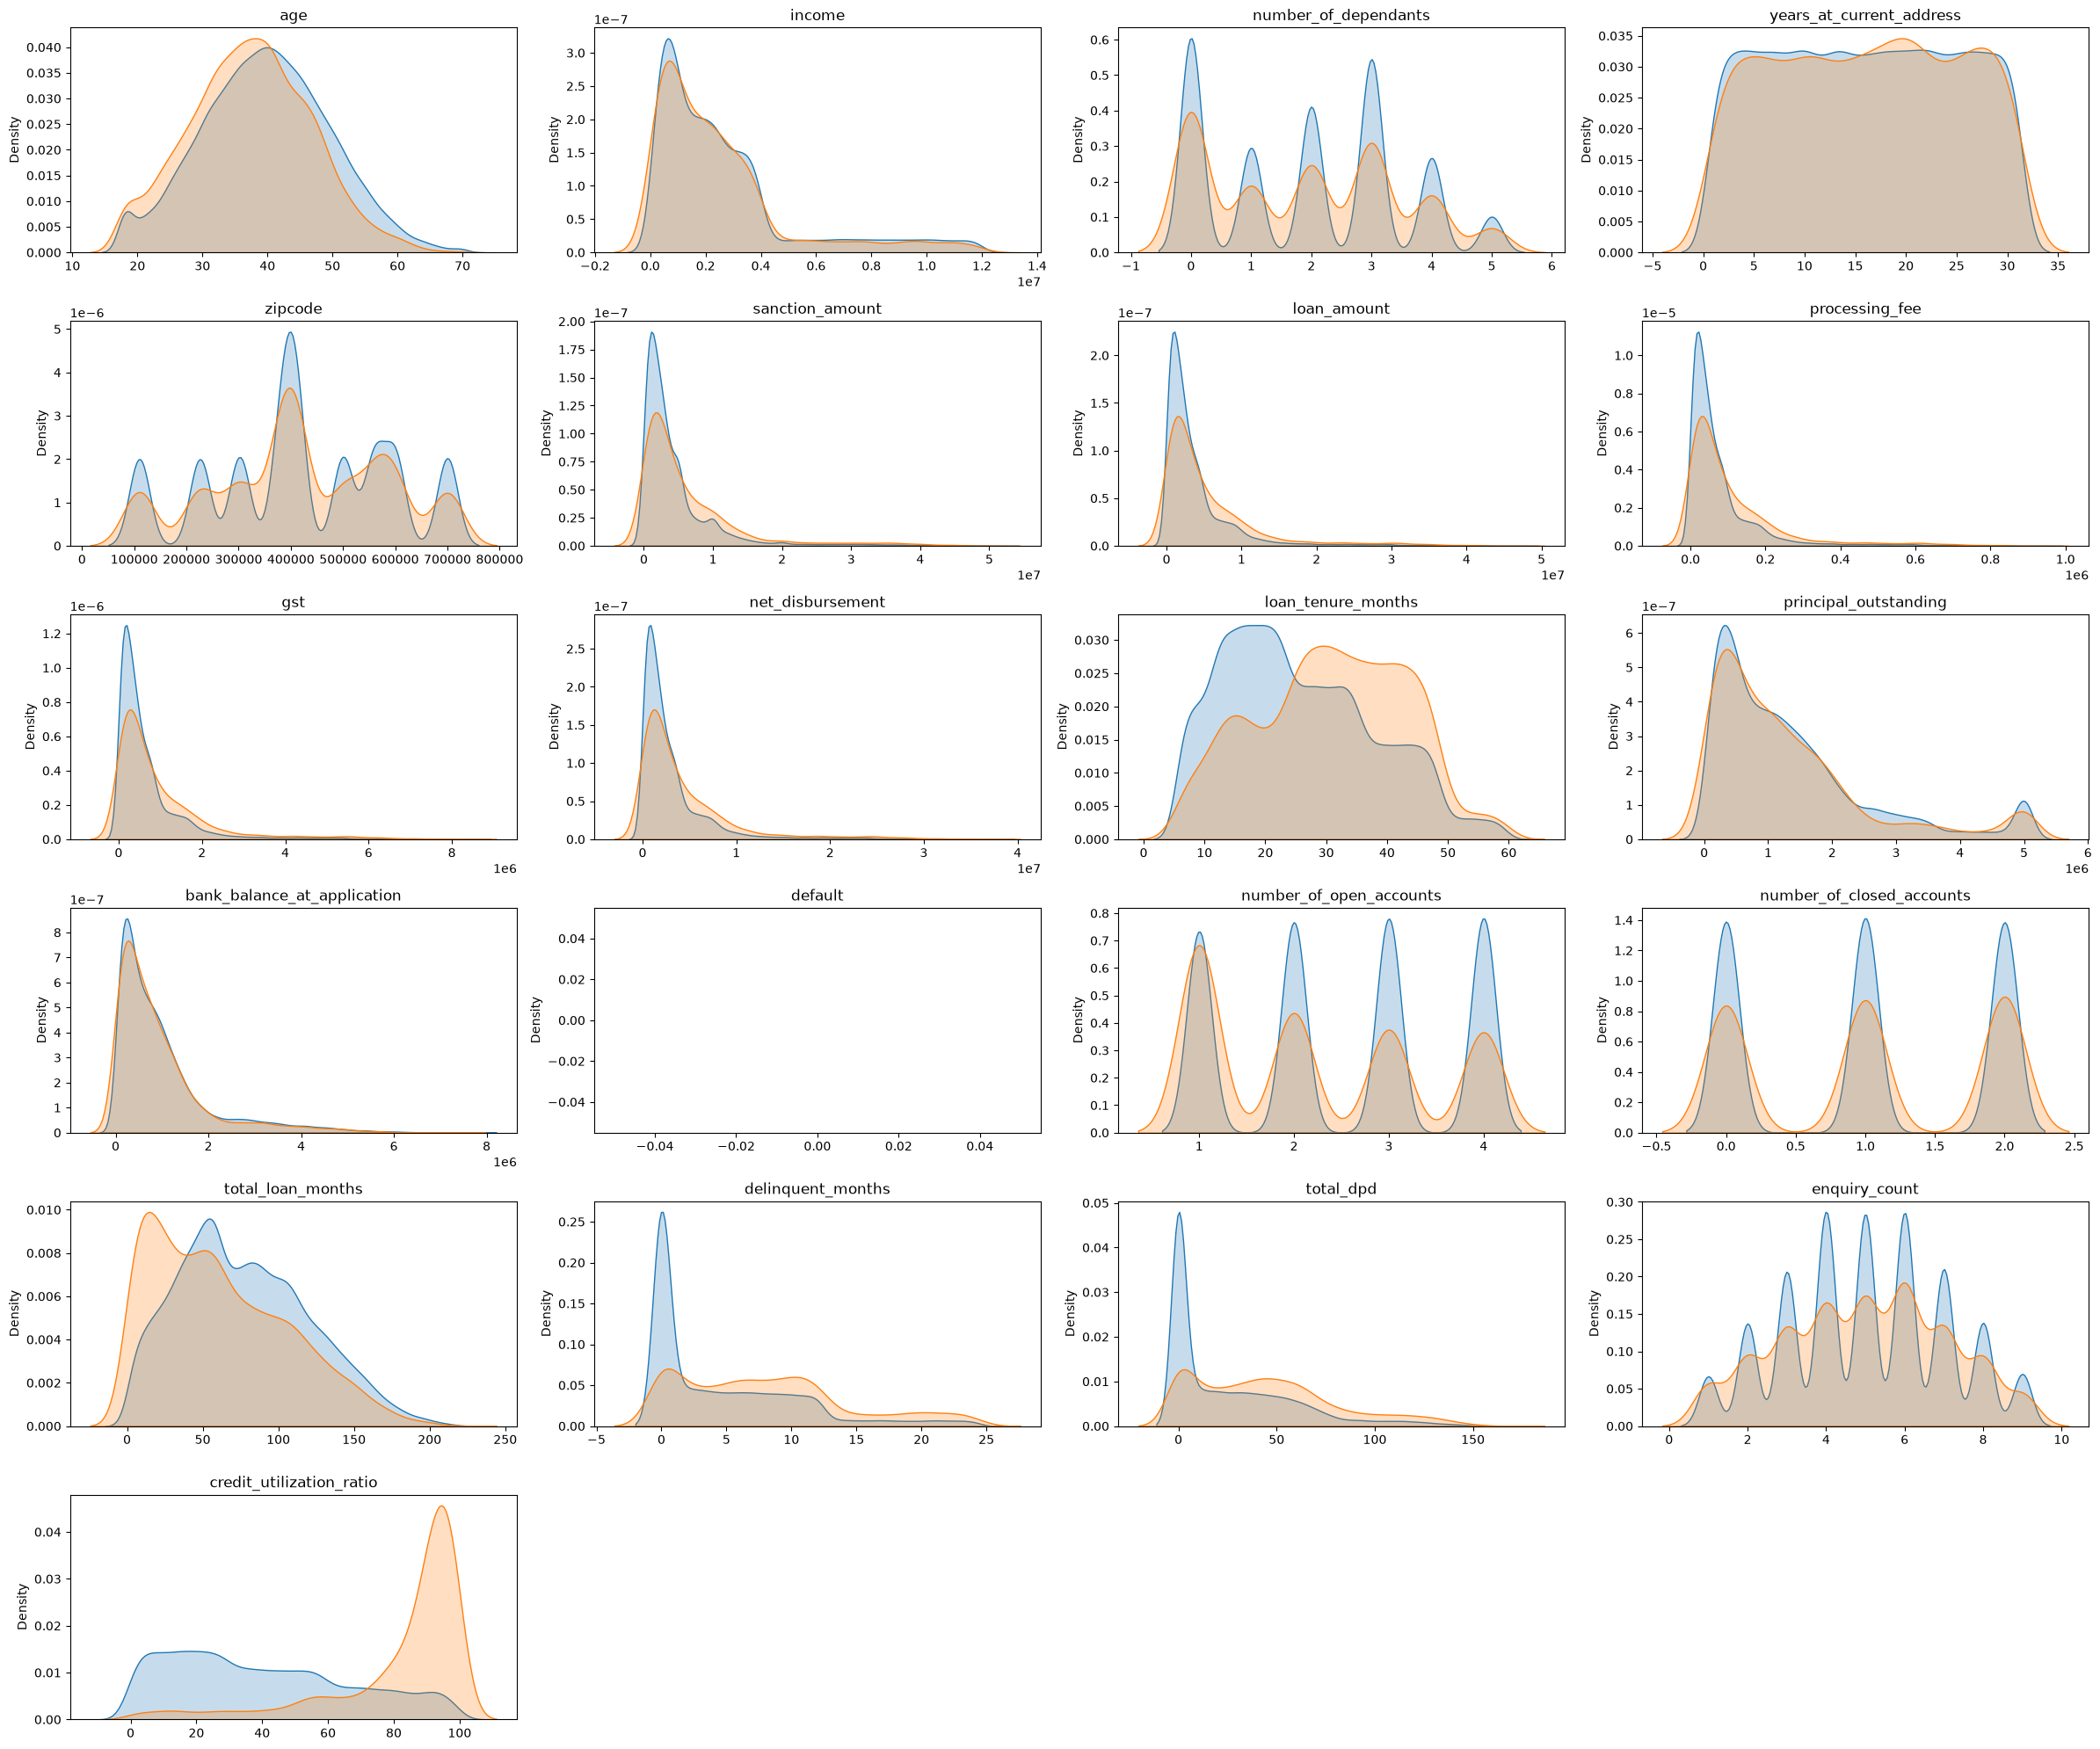

In [27]:
plt.figure(figsize=(24, 20))  # Width, height in inches

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1)  # 1 row, 4 columns, ith subplot
    sns.kdeplot(df[col][df['default']==0], fill=True, label='default=0')
    sns.kdeplot(df[col][df['default']==1], fill=True, label='default=1')
    plt.title(col)        
    plt.xlabel('')
    
plt.tight_layout()
plt.show()

**Insights**

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence these 4 looks like strong predictors
1. In remaining columns the distributions do not give any obvious insights
1. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later

<h3 style="color:blue" align="center">Feature Engineering, Feature Selection</h3>

#### Calculate loan to income Ratio

In [28]:
df["loan_to_income"] = round(df['loan_amount']/df["income"],2)
df["loan_to_income"].describe()

count   49985.00
mean        1.56
std         0.97
min         0.30
25%         0.77
50%         1.16
75%         2.45
max         4.59
Name: loan_to_income, dtype: float64

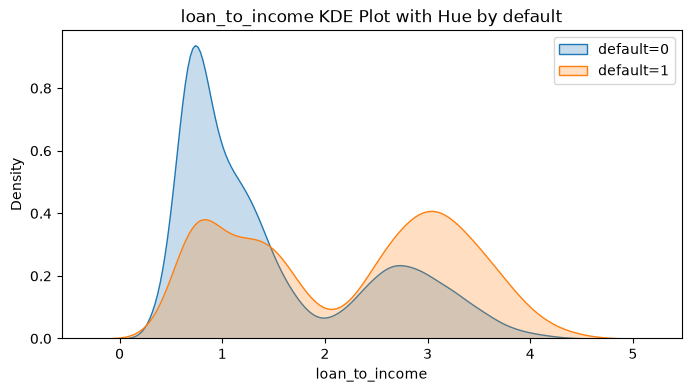

In [29]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df['loan_to_income'][df['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df['loan_to_income'][df['default'] == 1], fill=True, label='default=1')
plt.title(f"loan_to_income KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**
1. Blue graph has majority of its values on lower side of LTI
2. Orange graph has many values when LTI is higher indicating that higher LTI means high risk loan

#### Find out delinquent Ratio

In [30]:
df['delinquent_ratio'] = (df["delinquent_months"] *100 / df["total_loan_months"] ).round(2)
df[["delinquent_months", "total_loan_months", 'delinquent_ratio']].head(4)

,delinquent_months,total_loan_months,delinquent_ratio
0,0,42,0.00
1,12,96,12.50
2,24,82,29.27
3,15,115,13.04


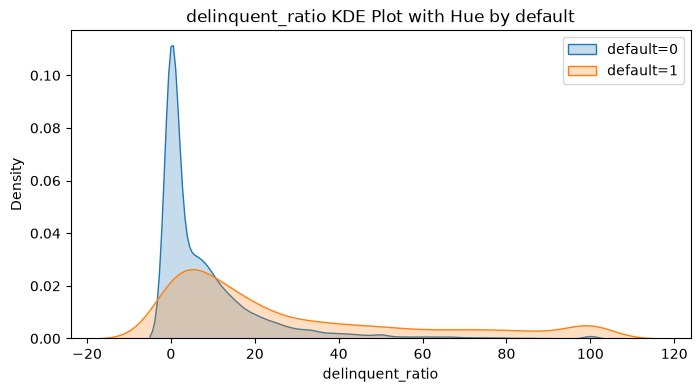

In [31]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df['delinquent_ratio'][df['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df['delinquent_ratio'][df['default'] == 1], fill=True, label='default=1')
plt.title(f"delinquent_ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**
1. Blue graph has majority of its values on lower side of LTI
2. Orange graph has many values when delinquency ratio is higher indicating some correlation on default

#### Generate Avg DPD Per Delinquency

In [32]:
df['avg_dpd_per_delinquency'] = np.where(
     df['delinquent_months'] != 0,
    (df['total_dpd'] / df['delinquent_months']).round(2),
    0)


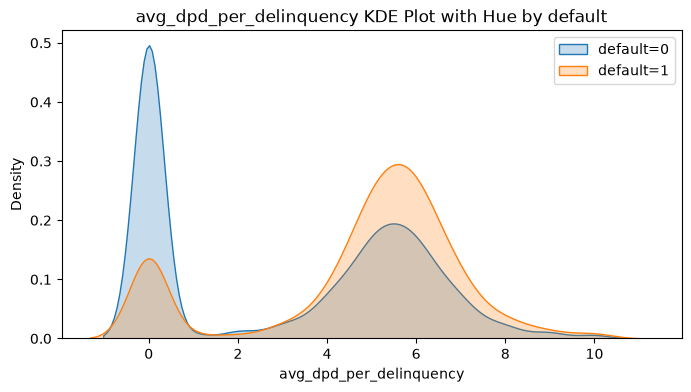

In [33]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df['avg_dpd_per_delinquency'][df['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df['avg_dpd_per_delinquency'][df['default'] == 1], fill=True, label='default=1')
plt.title(f"avg_dpd_per_delinquency KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**

1. Graph clearly shows more occurances of default cases when avg_dpd_per_delinquency is high. This means this column is a strong predictor

### Remove columns that are just unique ids and don't have influence on target

In [34]:
df.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

### Remove columns that business contact person asked us to remove

In [35]:
df = df.drop(['cust_id', 'loan_id', 'disbursal_date', 'installment_start_dt', 'loan_amount', 'income', 
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis="columns")

In [36]:
df.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'default', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

# Feature Selection: Numerical Column

In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Column'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

# OR

In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    # 1. Create a new DataFrame using a dictionary for cleaner syntax
    vif_df = pd.DataFrame({"Feature": data.columns})
    
    # 2. Calculate the VIF score for each column index
    vif_df["VIF"] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    
    # 3. Sort values to easily see the highest multicollinearity at the top
    return vif_df.sort_values(by="VIF", ascending=False).reset_index(drop=True)

In [39]:
data = df.select_dtypes(['int64', 'float64'])
calculate_vif(data)

c:\Users\Admin\.conda\envs\spyder-env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\.conda\envs\spyder-env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\.conda\envs\spyder-env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\.conda\envs\spyder-env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().r

,Feature,VIF
0,net_disbursement,1000799917193443.50
1,processing_fee,1000799917193443.50
2,gst,1000799917193443.50
3,sanction_amount,65.66
4,principal_outstanding,7.58
5,bank_balance_at_application,5.09
6,loan_to_income,2.84
7,loan_tenure_months,1.74
8,delinquent_ratio,1.60
9,number_of_open_accounts,1.58


In [40]:
df = df.drop(columns = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement','principal_outstanding'])
df.head(1)


,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,...,loan_tenure_months,bank_balance_at_application,default,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
0,44,M,Married,Self-Employed,3,Owned,27,Delhi,Delhi,110001,...,33,873386,0,1,1,3,7,0.95,0.00,0.00


--- Variance Inflation Factor (VIF) ---
                        Feature  VIF
0                loan_to_income 1.81
1            loan_tenure_months 1.70
2              delinquent_ratio 1.60
3       number_of_open_accounts 1.57
4                       default 1.44
5                 enquiry_count 1.42
6       avg_dpd_per_delinquency 1.30
7      credit_utilization_ratio 1.23
8                           age 1.12
9          number_of_dependants 1.07
10  bank_balance_at_application 1.00
11     years_at_current_address 1.00
12    number_of_closed_accounts 1.00
13                      zipcode 1.00


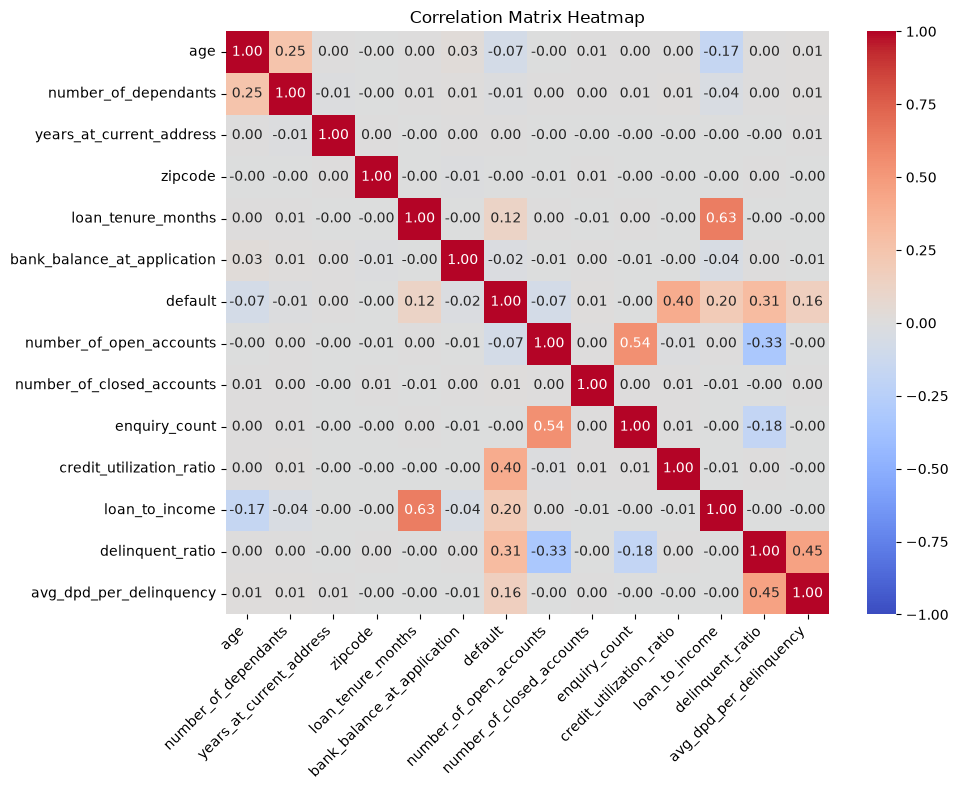

In [41]:
# 1. Isolate numerical data for VIF and Correlation calculations
numeric_data = df.select_dtypes(include=['int64', 'float64'])

# 2. Calculate and explicitly print the VIF results
vif_results = calculate_vif(numeric_data)
print("--- Variance Inflation Factor (VIF) ---")
print(vif_results)

# 3. Plot the Correlation Heatmap
plt.figure(figsize=(10, 8))

# CRITICAL FIX: Added .corr() and a colormap (cmap) to make correlations visually distinct
sns.heatmap(numeric_data.corr(), annot=True, fmt='0.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.title("Correlation Matrix Heatmap")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Feature Selection: Categorical Features

default is a target variable and we can see some class imbalance here. We will address it later on.
### Train Test split
We perform train test split before doing EDA to prevent data leakage. We don't want test set (which is part of the entire dataset) to influence EDA or any decisions on feature engineering. 

In [43]:
X = df.drop('default', axis=1)
Y = df["default"]

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=42, test_size=0.25, stratify=Y)


df_train =pd.concat([X_train, Y_train], axis = 1)
df_test =pd.concat([X_test, Y_test], axis = 1)

df_train.shape, df_test.shape


((37488, 22), (12497, 22))